# 01 · Data, patient-separated split and anchor replication

**Project:** DAN-MMGradCAM: reliability of paired 1D-signal and 2D-image Grad-CAM explanations for ECG arrhythmia classification (COE 691 final project).

This notebook covers the data and the classifiers that every explanation analysis depends on:

1. the Chapman–Shaoxing Lead-II cohort and the patient-separated split into train/validation/test,
2. the test accuracy of the replicated MM-GradCAM 1D and 2D CNNs, compared with the published anchor (Duranay et al., 2026),
3. the explanation cohort: test recordings classified correctly by both CNNs.

**Inputs** (archived HPC outputs in `data/archived/`): split manifests, test predictions written with the Grad-CAM maps, and the Module 2 record table (predictions on re-rendered images).
Training itself (`src/hpc_pipeline/01_data_and_training/`) needs the raw ECGs and a GPU and was run on the KFUPM HPC; see notebook 06.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().resolve().parent          # repository root (notebooks/ is one level down)
sys.path.insert(0, str(ROOT / 'src'))
ARCH = ROOT / 'data' / 'archived'           # archived HPC outputs (inputs of this notebook)
TAB = ROOT / 'results' / 'tables'           # tables written by the notebooks
FIG = ROOT / 'results' / 'figures'          # figures written by the notebooks (used in the report)
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 4)
warnings.filterwarnings('ignore', category=RuntimeWarning)
CLASSES = ['AFib', 'GSVT', 'SB', 'SR']
def show(name, width=900):
    """Display a figure that a plotting function saved to results/figures."""
    display(Image(filename=str(FIG / f'{name}.png'), width=width))
print('repository root:', ROOT.name)

repository root: DAN-MMGradCAM


## 1. Cohort and split

In [2]:
meta = json.loads((ARCH / 'split/test_split_1054_metadata.json').read_text())
test = pd.read_csv(ARCH / 'split/test_split_1054.csv')
train = pd.read_csv(ARCH / 'split/train_split.csv')
N_TOTAL = 10588                      # final cohort, one recording per patient (frozen in build_frozen_split.py)
n_val = N_TOTAL - len(train) - len(test)
split = pd.DataFrame({'split': ['train', 'validation', 'test', 'total'],
                      'recordings': [len(train), n_val, len(test), N_TOTAL]})
assert len(train) == 8475 and n_val == 1059 and len(test) == 1054
assert set(train.cohort_index).isdisjoint(test.cohort_index), 'train and test overlap'
print('Overlap between train and test cohort indices:', len(set(train.cohort_index) & set(test.cohort_index)))
print('Test class counts (metadata):', meta['class_counts'])
split

Overlap between train and test cohort indices: 0
Test class counts (metadata): {'AFib': 222, 'GSVT': 222, 'SB': 388, 'SR': 222}


,split,recordings
0,train,8475
1,validation,1059
2,test,1054
3,total,10588


In [3]:
both = pd.concat([train.assign(split='train'), test.assign(split='test')], ignore_index=True)
counts = pd.crosstab(both.class_name, both.split)
counts.loc['total'] = counts.sum()
counts

split,test,train
class_name,,
AFib,222,1764
GSVT,222,1824
SB,388,3096
SR,222,1791
total,1054,8475


Each recording is 10 s of Lead II sampled at 500 Hz (5000 samples). Because the cohort holds exactly one recording per patient,
a split by recording is also a split by patient. The z-score scaler of the 1D branch is fitted on the 9534 non-test recordings only.

## 2. Replication of the anchor CNNs

In [4]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_recall_fscore_support
p1 = pd.read_csv(ARCH / 'replication/1d_test_predictions.csv')
p2 = pd.read_csv(ARCH / 'replication/2d_test_predictions.csv')
assert len(p1) == len(p2) == 1054 and set(p1.cohort_index) == set(test.cohort_index)
ANCHOR = {'1D': 93.07, '2D': 97.44}          # accuracy reported by Duranay et al. (2026)
rows, per_class = [], []
for name, d in (('1D', p1), ('2D', p2)):
    y, yhat = d.true_class, d.predicted_class
    rows.append({'branch': name, 'anchor_acc_%': ANCHOR[name], 'replication_acc_%': 100 * accuracy_score(y, yhat),
                 'macro_F1_%': 100 * f1_score(y, yhat, average='macro'),
                 'UAR_%': 100 * recall_score(y, yhat, average='macro')})
    pr, rc, f1, sup = precision_recall_fscore_support(y, yhat, labels=CLASSES)
    for c, a, b, f, s in zip(CLASSES, pr, rc, f1, sup):
        per_class.append({'branch': name, 'class': c, 'precision_%': 100 * a, 'recall_%': 100 * b, 'F1_%': 100 * f, 'n': s})
rep = pd.DataFrame(rows); rep_cls = pd.DataFrame(per_class)
rep.to_csv(TAB / 'replication_accuracy.csv', index=False); rep_cls.to_csv(TAB / 'replication_per_class.csv', index=False)
display(rep.round(2))
rep_cls.round(1)

,branch,anchor_acc_%,replication_acc_%,macro_F1_%,UAR_%
0,1D,93.07,94.78,94.57,94.53
1,2D,97.44,97.06,96.73,96.65


,branch,class,precision_%,recall_%,F1_%,n
0,1D,AFib,94.3,96.4,95.3,222
1,1D,GSVT,94.3,96.4,95.3,222
2,1D,SB,95.4,96.1,95.8,388
3,1D,SR,94.7,89.2,91.9,222
4,2D,AFib,94.6,95.5,95.1,222
5,2D,GSVT,95.1,96.8,96.0,222
6,2D,SB,98.5,99.2,98.8,388
7,2D,SR,99.1,95.0,97.0,222


The 2D accuracy recomputed here (97.06 %) is from the predictions saved together with the Grad-CAM maps.
The training script's own evaluation of the selected checkpoint reported 96.68 %; that number comes from the HPC training log and is not recomputed here.

saved fig_replication_confusion


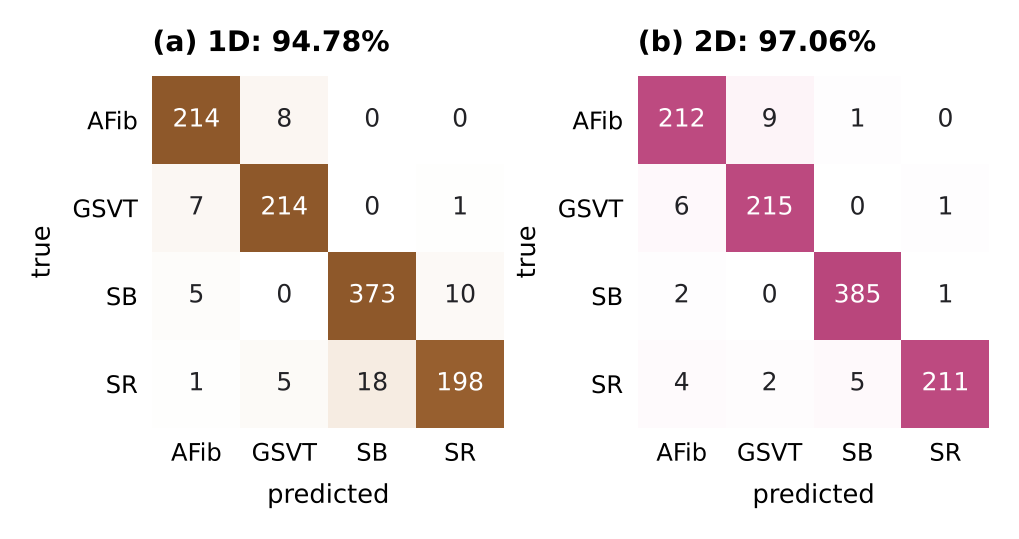

In [5]:
import dan_figures as F
F.fig_confusion(p1, p2, FIG)
show('fig_replication_confusion', 650)

## 3. Explanation cohort

In [6]:
rec = pd.read_csv(ARCH / 'module2/noise_stability_records.csv')
both_orig = (p1.set_index('cohort_index').correct & p2.set_index('cohort_index').eval('true_class == predicted_class'))
rec['correct_1d'] = rec.pred_1d == rec.class_name
rec['correct_2d_rerendered'] = rec.pred_2d == rec.class_name
agree_2d = (rec.set_index('cohort_index').pred_2d == p2.set_index('cohort_index').predicted_class).sum()
cohort = pd.DataFrame({
    'quantity': ['correct in both CNNs (original images)', '2D correct on re-rendered images',
                 '2D re-rendered prediction = original prediction', 'primary explanation cohort (both correct, re-rendered)'],
    'n': [int(both_orig.sum()), int(rec.correct_2d_rerendered.sum()), int(agree_2d),
          int((rec.correct_1d & rec.correct_2d_rerendered).sum())]})
cohort['% of 1054'] = 100 * cohort.n / 1054
cohort.to_csv(TAB / 'explanation_cohort.csv', index=False)
cohort.round(1)

,quantity,n,% of 1054
0,correct in both CNNs (original images),980,93.0
1,2D correct on re-rendered images,975,92.5
2,2D re-rendered prediction = original prediction,996,94.5
3,"primary explanation cohort (both correct, re-r...",939,89.1


In [7]:
tab = rec.groupby('class_name').agg(n=('cohort_index', 'size'), acc_1d=('correct_1d', 'mean'),
                                    acc_2d_rerendered=('correct_2d_rerendered', 'mean'),
                                    both_correct=('correct_1d', lambda s: int((s & rec.loc[s.index, 'correct_2d_rerendered']).sum())))
tab.loc['All'] = [len(rec), rec.correct_1d.mean(), rec.correct_2d_rerendered.mean(), int((rec.correct_1d & rec.correct_2d_rerendered).sum())]
tab.round(3)

,n,acc_1d,acc_2d_rerendered,both_correct
class_name,,,,
AFib,222.0,0.964,0.955,208.0
GSVT,222.0,0.964,0.905,196.0
SB,388.0,0.961,0.974,366.0
SR,222.0,0.892,0.829,169.0
All,1054.0,0.948,0.925,939.0


**Summary.** The replicated 1D CNN (94.78 %) exceeds the published 1D accuracy and the 2D CNN (97.06 %) is within 0.4 points of it.
Module 2 regenerates every image, including the unperturbed one, so all explanation analyses use the **939** test recordings that are correct in both branches under re-rendering.